# Fraud Detection Analytics

**Dataset:** Credit Card Transaction Fraud Detection (Sparkov simulated data, Kaggle)

**Objective:** To clean and explore credit card transaction data, detect fraudulent
transactions using anomaly detection (DBSCAN) and classification algorithms, and
identify the different types of fraud present in the data.

In [39]:
# Importing the required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
sns.set_style('whitegrid')

In [40]:
# Loading the Dataset
df = pd.read_csv(r"C:\Users\sreya\Downloads\fraud dataset\fraudTrain.csv")
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [41]:
df.shape

(1296675, 23)

### Understanding the structure of the dataset

Before doing any analysis we need to know what kind of information each column holds
and whether the data is complete.

In [42]:
df.columns.tolist()

['Unnamed: 0',
 'trans_date_trans_time',
 'cc_num',
 'merchant',
 'category',
 'amt',
 'first',
 'last',
 'gender',
 'street',
 'city',
 'state',
 'zip',
 'lat',
 'long',
 'city_pop',
 'job',
 'dob',
 'trans_num',
 'unix_time',
 'merch_lat',
 'merch_long',
 'is_fraud']

In [43]:
df.dtypes

Unnamed: 0                 int64
trans_date_trans_time     object
cc_num                     int64
merchant                  object
category                  object
amt                      float64
first                     object
last                      object
gender                    object
street                    object
city                      object
state                     object
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                       object
dob                       object
trans_num                 object
unix_time                  int64
merch_lat                float64
merch_long               float64
is_fraud                   int64
dtype: object

In [44]:
df.info

<bound method DataFrame.info of          Unnamed: 0 trans_date_trans_time               cc_num  \
0                 0   2019-01-01 00:00:18     2703186189652095   
1                 1   2019-01-01 00:00:44         630423337322   
2                 2   2019-01-01 00:00:51       38859492057661   
3                 3   2019-01-01 00:01:16     3534093764340240   
4                 4   2019-01-01 00:03:06      375534208663984   
...             ...                   ...                  ...   
1296670     1296670   2020-06-21 12:12:08       30263540414123   
1296671     1296671   2020-06-21 12:12:19     6011149206456997   
1296672     1296672   2020-06-21 12:12:32     3514865930894695   
1296673     1296673   2020-06-21 12:13:36     2720012583106919   
1296674     1296674   2020-06-21 12:13:37  4292902571056973207   

                                    merchant       category     amt  \
0                 fraud_Rippin, Kub and Mann       misc_net    4.97   
1            fraud_Heller, Gutman

The dataset has 1,296,675 transactions and 23 columns. The columns can be grouped as follows:

- **Transaction details:** date and time of the transaction, amount, merchant name, merchant category
- **Customer details:** card number, name, gender, address, city, state, zip code, job, date of birth
- **Location details:** latitude and longitude of the customer's home and of the merchant
- **Target column:** is_fraud, which is 1 if the transaction was fraud and 0 if it was genuine

Our job is to study all the other columns and find out which of them help us identify
the transactions marked as fraud.

## Checking for null values

In [45]:
df.isnull().sum()

Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

As we can see there are no null values. So we do not need to fill or drop anything at this stage, and we can move straight
to the next check.

## Checking for duplicate values

Duplicate rows are the exact same record entered twice. They need to be removed because
they give extra weight to the same information and can mislead the model.

In [46]:
df.duplicated().sum()

np.int64(0)

There are zero duplicate rows in the dataset. Every transaction is unique, which makes
sense because each row also carries its own unique transaction ID.

So our data is clean on both counts — no missing values and no duplicates.

## Dropping the unnecessary columns

Not every column helps us find fraud. We will remove five of them

In [47]:
df = df.drop(['Unnamed: 0', 'trans_num', 'first', 'last', 'street'], axis=1)
df.shape

(1296675, 18)

In [48]:
# Changing the data type of some columns         
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
df['dob'] = pd.to_datetime(df['dob'])

df[['trans_date_trans_time', 'dob']].dtypes

trans_date_trans_time    datetime64[ns]
dob                      datetime64[ns]
dtype: object

## Feature Engineering

We will create six new columns in total. First, the three time-based ones:

1. **hour** — the hour of the day the transaction happened (0 to 23)
2. **day_of_week** — which day of the week it was (0 = Monday, 6 = Sunday)
3. **month** — which month it was

The hour is the most important of these. Fraudsters prefer late-night hours when the real
cardholder is asleep and not checking their phone, so the time of day is often a strong clue

In [49]:
df['hour'] = df['trans_date_trans_time'].dt.hour
df['day_of_week'] = df['trans_date_trans_time'].dt.dayofweek
df['month'] = df['trans_date_trans_time'].dt.month

df[['trans_date_trans_time', 'hour', 'day_of_week', 'month']].head()

,trans_date_trans_time,hour,day_of_week,month
0,2019-01-01 00:00:18,0,1,1
1,2019-01-01 00:00:44,0,1,1
2,2019-01-01 00:00:51,0,1,1
3,2019-01-01 00:01:16,0,1,1
4,2019-01-01 00:03:06,0,1,1


###### Calculating the customer's age

The date of birth on its own is not useful to a model. a birth year of 1988 means nothing
by itself. What matters is how old the customer was when the transaction took place.

So we subtract the date of birth from the transaction date, which gives us the number of days
in between, and divide by 365.25 to convert it into years. The .25 accounts for leap years.

In [50]:
df['age'] = ((df['trans_date_trans_time'] - df['dob']).dt.days / 365.25)
df['age'] = df['age'].round().astype(int)

df[['dob', 'trans_date_trans_time', 'age']].head()

,dob,trans_date_trans_time,age
0,1988-03-09,2019-01-01 00:00:18,31
1,1978-06-21,2019-01-01 00:00:44,41
2,1962-01-19,2019-01-01 00:00:51,57
3,1967-01-12,2019-01-01 00:01:16,52
4,1986-03-28,2019-01-01 00:03:06,33


##### Calculating the distance between the customer and the merchant

The dataset gives us four location columns. the latitude and longitude of the customer's home,
and the latitude and longitude of the merchant. Four separate numbers like these mean nothing
to a model on their own.

What is meaningful is the distance between the two points. A transaction happening far from
where the customer lives is worth a second look.

We use the haversine formula, which calculates the true distance between two points on the
surface of the earth, taking its curvature into account. The answer comes out in kilometres.

In [51]:
R = 6371   # radius of the earth in kilometres

lat1 = np.radians(df['lat'])
lon1 = np.radians(df['long'])
lat2 = np.radians(df['merch_lat'])
lon2 = np.radians(df['merch_long'])

a = np.sin((lat2 - lat1)/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1)/2)**2
df['distance'] = (2 * R * np.arcsin(np.sqrt(a))).round(2)

df[['lat', 'long', 'merch_lat', 'merch_long', 'distance']].head()

,lat,long,merch_lat,merch_long,distance
0,36.0788,-81.1781,36.011293,-82.048315,78.60
1,48.8878,-118.2105,49.159047,-118.186462,30.21
2,42.1808,-112.2620,43.150704,-112.154481,108.21
3,46.2306,-112.1138,47.034331,-112.561071,95.67
4,38.4207,-79.4629,38.674999,-78.632459,77.56


##### Comparing each transaction to the card's own spending habit

This is the most important column we will create.

Looking at the amount alone tells us very little. A ₹5,000 transaction is perfectly normal for
someone who usually spends large amounts, but highly suspicious for someone whose usual
transaction is ₹200. The same number means two completely different things depending on whose
card it is.

So instead of judging the amount on its own, we compare every transaction against the average
spending of **that particular card**. We group the data by card number, find each card's average
transaction amount, and divide every transaction by its own card's average.

A value of 1 means the transaction was exactly average for that card. A value of 5 means the
customer spent five times their usual amount, which is the kind of behaviour worth investigating.

In [52]:
card_average = df.groupby('cc_num')['amt'].transform('mean')
df['amt_ratio'] = (df['amt'] / card_average).round(2)

df[['cc_num', 'amt', 'amt_ratio']].head()

,cc_num,amt,amt_ratio
0,2703186189652095,4.97,0.06
1,630423337322,107.23,1.99
2,38859492057661,220.11,3.34
3,3534093764340240,45.00,0.62
4,375534208663984,41.96,0.44


In [54]:
# Dropping the columns we no longer need

df = df.drop(['trans_date_trans_time', 'dob', 'lat', 'long', 'merch_lat', 'merch_long',
              'cc_num', 'zip', 'merchant', 'city', 'job', 'state', 'unix_time'], axis=1)

print(df.shape)
df.head()

(1296675, 11)


,category,amt,gender,city_pop,is_fraud,hour,day_of_week,month,age,distance,amt_ratio
0,misc_net,4.97,F,3495,0,0,1,1,31,78.60,0.06
1,grocery_pos,107.23,F,149,0,0,1,1,41,30.21,1.99
2,entertainment,220.11,M,4154,0,0,1,1,57,108.21,3.34
3,gas_transport,45.00,M,1939,0,0,1,1,52,95.67,0.62
4,misc_pos,41.96,M,99,0,0,1,1,33,77.56,0.44


In [55]:
df.shape

(1296675, 11)

In [56]:
print(df.columns.tolist())

['category', 'amt', 'gender', 'city_pop', 'is_fraud', 'hour', 'day_of_week', 'month', 'age', 'distance', 'amt_ratio']


##### Checking the target variable

`is_fraud` is the column we are trying to predict. A value of 1 means the transaction was
fraud and 0 means it was genuine. Before anything else, we need to see how many of each
we have, because that shapes every decision we make later.

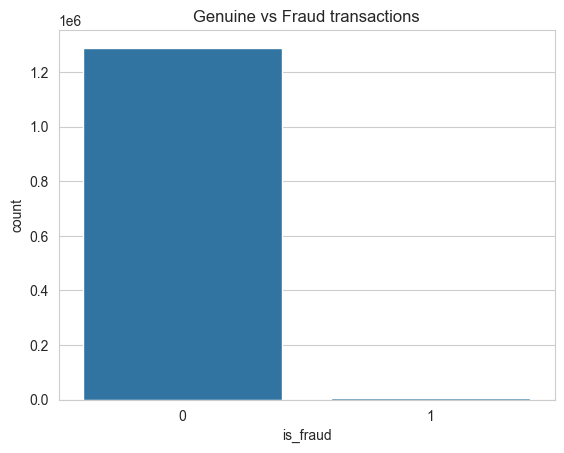

is_fraud
0    1289169
1       7506
Name: count, dtype: int64

is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64


In [57]:
ax = sns.countplot(x='is_fraud', data=df)
plt.title('Genuine vs Fraud transactions')
plt.show()

print(df['is_fraud'].value_counts())
print()
print(df['is_fraud'].value_counts(normalize=True) * 100)

## Taking a sample of the data

Our dataset has almost 13 lakh rows. Some of the techniques we are about to use — the pairplot
and the DBSCAN clustering algorithm — work by comparing every row against every other row. On
13 lakh rows that runs into billions of comparisons, which would either freeze the laptop or
run out of memory.

So from here onwards we will work on a **sample of 50,000 transactions**.

The important part is *how* the sample is taken. We use **stratified sampling**, which keeps
the same fraud-to-genuine ratio as the original data. An ordinary random sample might by chance
pick up very few fraud cases and spoil the whole study. Stratified sampling guarantees that our
sample is a fair miniature version of the full dataset.

In [58]:
from sklearn.model_selection import train_test_split

df_sample, _ = train_test_split(df,
                                train_size=50000,
                                stratify=df['is_fraud'],
                                random_state=42)

df_sample = df_sample.reset_index(drop=True)

print(df_sample.shape)
print()
print(df_sample['is_fraud'].value_counts())
print()
print(df_sample['is_fraud'].value_counts(normalize=True) * 100)

(50000, 11)

is_fraud
0    49711
1      289
Name: count, dtype: int64

is_fraud
0    99.422
1     0.578
Name: proportion, dtype: float64


Our sample has 50,000 transactions of which **289 are fraud (0.578%)**. The full dataset had
0.5789% fraud, so the ratio has been preserved almost exactly. This sample is a fair
representation of the original data and we can safely continue our analysis on it.

In [59]:
df_sample.describe()

,amt,city_pop,is_fraud,hour,day_of_week,month,age,distance,amt_ratio
count,50000.000000,5.000000e+04,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000
mean,69.596655,8.841596e+04,0.005780,12.823820,3.075940,6.18550,45.938040,76.101204,0.986733
std,155.951932,2.983261e+05,0.075807,6.794482,2.203304,3.41042,17.368735,29.088295,2.226825
min,1.000000,2.300000e+01,0.000000,0.000000,0.000000,1.00000,14.000000,0.070000,0.010000
25%,9.610000,7.440000e+02,0.000000,7.000000,1.000000,3.00000,33.000000,55.490000,0.150000
50%,47.280000,2.470000e+03,0.000000,14.000000,3.000000,6.00000,44.000000,78.260000,0.670000
75%,82.492500,2.032800e+04,0.000000,19.000000,5.000000,9.00000,57.000000,98.440000,1.180000
max,13536.840000,2.906700e+06,1.000000,23.000000,6.000000,12.00000,96.000000,146.130000,175.790000


The summary tells us the data is valid — there are no negative amounts, no impossible ages and
no missing counts. Every column has all 50,000 entries. A few observations stand out:

**1. The amount column is heavily right-skewed.** The average transaction is ₹69.60 but the
median is only ₹47.28. When the mean is much larger than the median it means a small number of
very large values are pulling the average up. The gap between the 75th percentile (₹82.49) and
the maximum (₹13,536.84) confirms this — three quarters of all transactions are under ₹83, yet
the largest is over ₹13,500. We will need to treat this skewness later.

**2. City population is even more skewed.** The median town has 2,470 people but the largest
city has 29 lakh. This column will also need a transformation.

**3. The distance column behaves oddly.** It runs from 0.07 km to only 146 km, and the mean
(76.10) and median (78.26) are almost identical, which means it is nearly symmetric. Real
customer-to-merchant distances would be heavily skewed, with most transactions happening close
to home and a few far away. The fact that this one is capped and evenly spread suggests the
simulator placed every merchant within a fixed radius of the customer. We should therefore not
expect this column to help much in detecting fraud, and we will verify that when we check the
correlations.

**4. The youngest customer is 14 years old**, which is unusual for a credit card holder. This is
an artefact of the simulator generating random dates of birth rather than a real data error,
but it is worth noting.

**5. `amt_ratio` has a mean close to 1**, which is expected since it was built by dividing each
transaction by its own card's average. The maximum of 175.79 means that somewhere in this
sample a customer spent 175 times their usual amount in a single transaction.

## Data Visualization

### Univariate analysis

Univariate analysis means studying one column at a time to understand how its values are spread
out, before we start looking at relationships between columns.

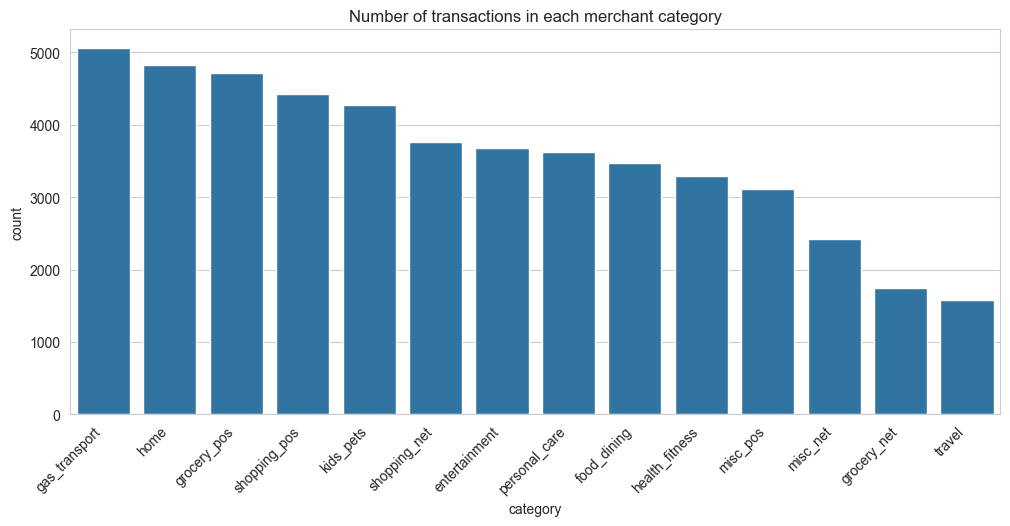

category
gas_transport     5062
home              4830
grocery_pos       4719
shopping_pos      4419
kids_pets         4277
shopping_net      3758
entertainment     3673
personal_care     3619
food_dining       3476
health_fitness    3299
misc_pos          3107
misc_net          2428
grocery_net       1751
travel            1582
Name: count, dtype: int64


In [61]:
plt.figure(figsize=(12,5))
ax = sns.countplot(x='category', data=df_sample,
                   order=df_sample['category'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title('Number of transactions in each merchant category')
plt.show()

print(df_sample['category'].value_counts())

The transactions are spread fairly evenly across the 14 merchant categories. `gas_transport`
is the most common with 5,062 transactions and `travel` the least common with 1,582. No single
category dominates the dataset.

Note that this chart only shows *how many* transactions happened in each category, not how many
of them were fraud. A category can be very common and still be perfectly safe. We will look at
the fraud rate per category in the bivariate analysis, and that is where the interesting
differences will appear.

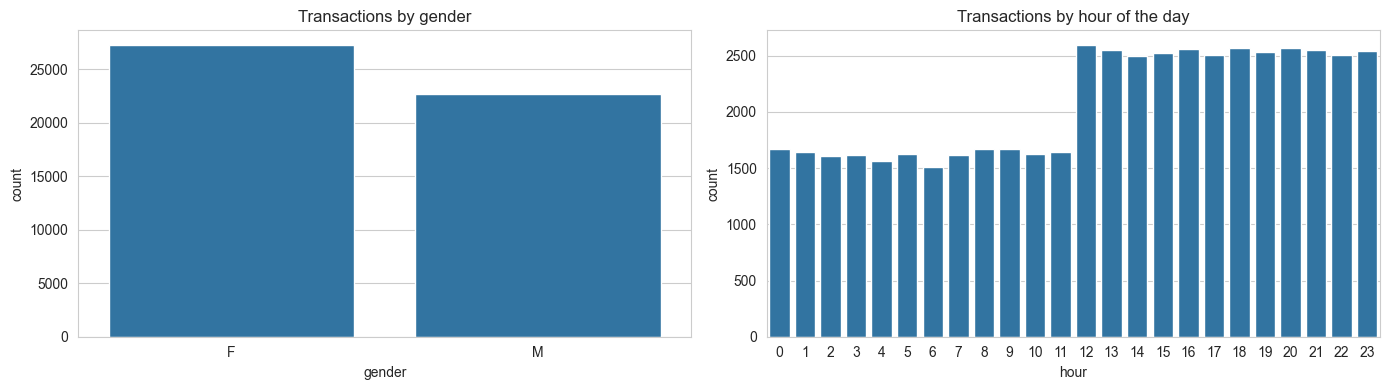

gender
F    27271
M    22729
Name: count, dtype: int64


In [62]:
fig, ax = plt.subplots(1, 2, figsize=(14,4))

sns.countplot(x='gender', data=df_sample, ax=ax[0])
ax[0].set_title('Transactions by gender')

sns.countplot(x='hour', data=df_sample, ax=ax[1])
ax[1].set_title('Transactions by hour of the day')

plt.tight_layout()
plt.show()

print(df_sample['gender'].value_counts())

**Gender:** The data has 27,271 female and 22,729 male customers, which is reasonably balanced
at roughly 55:45. Neither group dominates.

**Hour of the day:** There is a clear jump at midday. Between midnight and 11 am there are
about 1,600 transactions per hour, and from noon to 11 pm this rises to about 2,500 per hour.
This makes sense, since people shop more in the afternoon and evening than in the early hours.

This chart is important for a reason that is easy to miss. It shows the *total* number of
transactions in each hour, not the number of frauds. So when we later find that a lot of fraud
happens at night, we must be careful not to confuse the two. The right question is not "how
many frauds happened in this hour" but "what percentage of the transactions in this hour were
fraud". We will use the fraud *rate* in our bivariate analysis for exactly this reason.

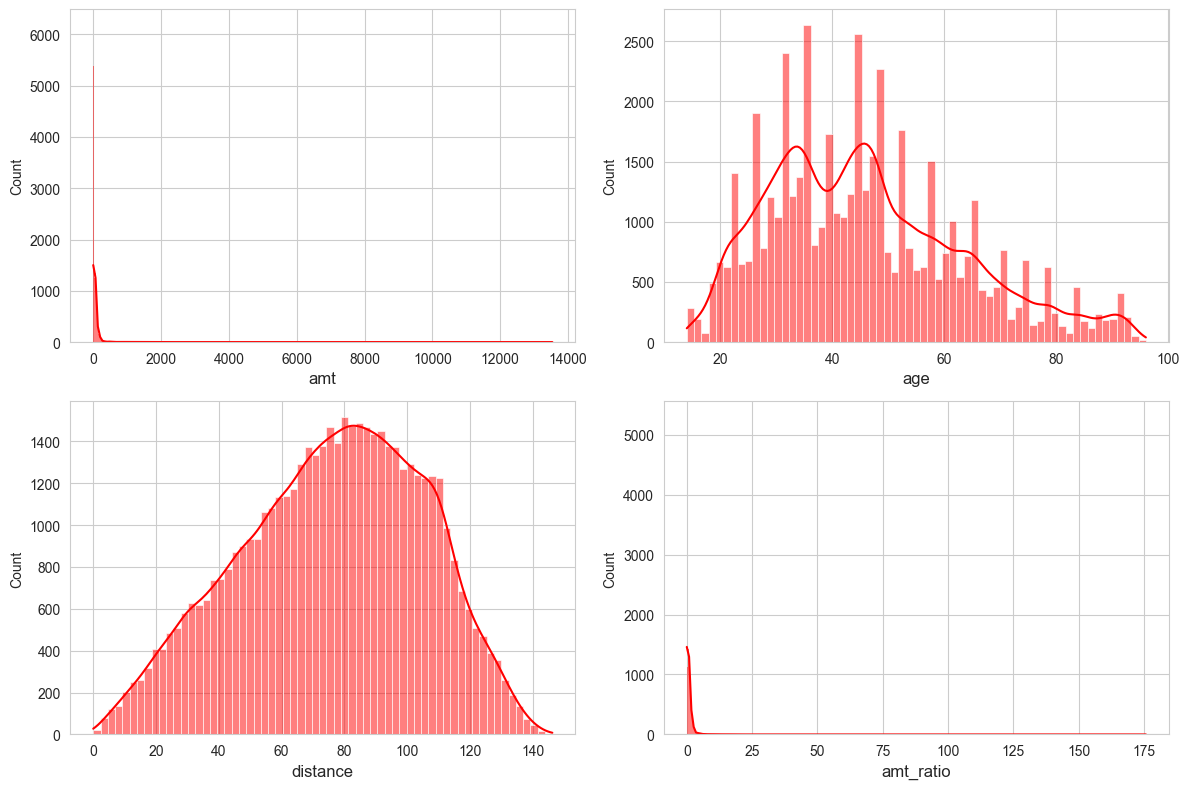

In [63]:
numerical_col = ['amt', 'age', 'distance', 'amt_ratio']

plt.figure(figsize=(12,8))
plotnumber = 1

for col in numerical_col:
    ax = plt.subplot(2, 2, plotnumber)
    sns.histplot(df_sample[col], kde=True, color='r')
    plt.xlabel(col, fontsize=12)
    plotnumber += 1

plt.tight_layout()
plt.show()

The four distributions tell us very different stories.

**amt** is extremely right-skewed. Almost every transaction is squeezed into the far-left bar
near zero, with a very thin tail stretching out to ₹13,500. This is the classic shape of
spending data — most purchases are small and a handful are very large.

**amt_ratio** has the same extreme shape, which is expected since it is built from the amount.
Most transactions sit near 1 (normal for that card) with a thin tail of unusual ones.

**age** is roughly bell-shaped, spread between 14 and 96 with most customers in their thirties
and forties. The spiky appearance is only because age is a whole number, so each year forms its
own bar. There is a mild right skew, with fewer customers at the older end.

**distance is the interesting one.** It forms an almost perfect symmetric bell curve centred
around 80 km, and stops dead at about 146 km. This is not how real-world data behaves. In
reality most people shop close to home and a few travel far, which would give a heavily
right-skewed curve with a long tail. A neat symmetric hump with a hard ceiling is the signature
of a computer generating random points within a fixed radius.

This tells us something important before we even build a model: **the distance column almost
certainly cannot help us detect fraud in this dataset.** It was manufactured the same way for
fraudulent and genuine transactions alike. We will test this properly in the correlation step
rather than just assuming it, but we should not be surprised when it turns out to be useless.

This is worth recording as a limitation of the dataset. Distance from home is one of the
strongest fraud signals in real banking systems, and here it simply does not exist.

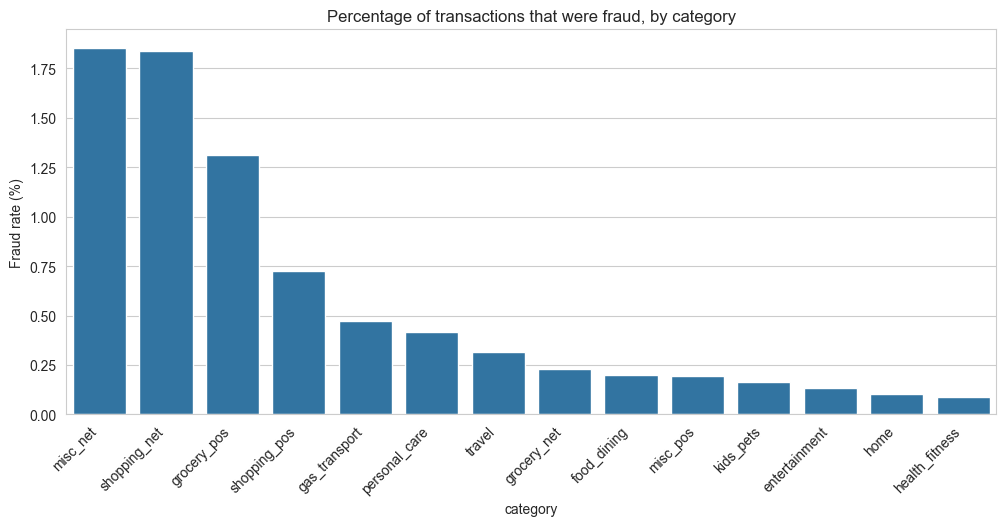

category
misc_net          1.853
shopping_net      1.836
grocery_pos       1.314
shopping_pos      0.724
gas_transport     0.474
personal_care     0.414
travel            0.316
grocery_net       0.228
food_dining       0.201
misc_pos          0.193
kids_pets         0.164
entertainment     0.136
home              0.104
health_fitness    0.091
Name: is_fraud, dtype: float64


In [64]:
plt.figure(figsize=(12,5))
fraud_rate_cat = df_sample.groupby('category')['is_fraud'].mean().sort_values(ascending=False) * 100

sns.barplot(x=fraud_rate_cat.index, y=fraud_rate_cat.values)
plt.xticks(rotation=45, ha='right')
plt.ylabel('Fraud rate (%)')
plt.title('Percentage of transactions that were fraud, by category')
plt.show()

print(fraud_rate_cat.round(3))

This is our first useful finding.

The fraud rate is very different from one category to another. `misc_net` has the highest at
**1.853%** and `health_fitness` the lowest at about **0.09%**. So the riskiest category is
about **20 times** more dangerous than the safest one.

The two worst categories are `misc_net` and `shopping_net`. The `_net` in their names means
these are **online purchases**. In an online purchase the card is never physically shown, so
a thief only needs the card number to use it. That is why online categories are the most
risky ones.

Now compare this with the earlier chart. `gas_transport` had the most transactions of all
(5,062), but its fraud rate is only 0.474%. `misc_net` had fewer than half as many
transactions but almost four times the fraud rate.

So a category being popular does not make it risky. These are two completely different things.

For a bank this is useful in a simple way. If you only have a small team to check suspicious
transactions, you should point them at online shopping, not at gym or health payments.

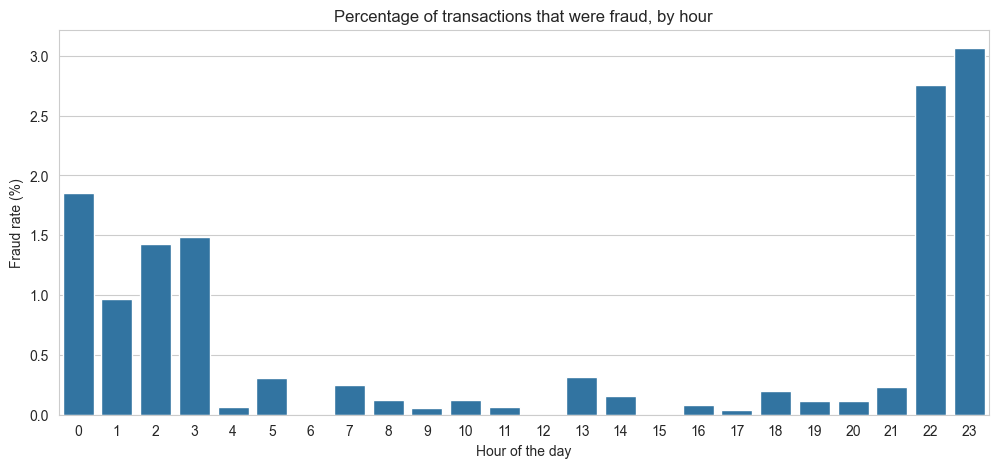

hour
0     1.853
1     0.971
2     1.429
3     1.485
4     0.064
5     0.307
6     0.000
7     0.248
8     0.120
9     0.060
10    0.123
11    0.061
12    0.000
13    0.313
14    0.160
15    0.000
16    0.078
17    0.040
18    0.194
19    0.118
20    0.117
21    0.235
22    2.753
23    3.064
Name: is_fraud, dtype: float64


In [65]:
plt.figure(figsize=(12,5))
fraud_rate_hour = df_sample.groupby('hour')['is_fraud'].mean() * 100

sns.barplot(x=fraud_rate_hour.index, y=fraud_rate_hour.values)
plt.ylabel('Fraud rate (%)')
plt.xlabel('Hour of the day')
plt.title('Percentage of transactions that were fraud, by hour')
plt.show()

print(fraud_rate_hour.round(3))

This is the clearest pattern we have found so far.

Look at the two tallest bars. At **11 pm the fraud rate is 3.064%** and at **10 pm it is
2.753%**. The hours just after midnight are also high — 1.853% at midnight, and around 1.4%
at 2 am and 3 am.

Now look at the daytime. From 4 am right through to 9 pm, almost every bar is below 0.3%.
At 6 am, noon and 3 pm the fraud rate is exactly **0%** — not a single fraud in our sample.

So fraud is packed into a six-hour window: **10 pm to 4 am**. Comparing the worst hour
(11 pm at 3.064%) with a normal evening hour (5 pm at 0.040%) gives a difference of more
than **70 times**.

The reason is simple and human. Fraudsters use stolen cards late at night because the real
owner is asleep. Nobody is checking their phone, nobody notices the SMS alert, and the theft
is not reported until the morning. By then the money is gone.

Remember the earlier chart showing that most transactions happen in the afternoon and evening.
Night hours have *fewer* transactions overall, but a much higher share of them are fraud. This
is why we measured the fraud *rate* instead of just counting frauds. Counting alone would have
hidden this completely.

### Creating a night-time column

The hour column runs from 0 to 23, and a model may struggle with that because hour 23 and
hour 0 are next to each other in real life but are as far apart as possible as numbers.

Since we can see clearly that fraud lives between 10 pm and 4 am, we create a simple yes/no
column called `is_night` which is 1 for those hours and 0 for everything else. This makes the
pattern much easier for any model to pick up.

In [66]:
df_sample['is_night'] = df_sample['hour'].isin([22, 23, 0, 1, 2, 3]).astype(int)

print(df_sample.groupby('is_night')['is_fraud'].agg(['count', 'sum', 'mean']))
print()
print("Fraud rate at night :", round(df_sample[df_sample['is_night']==1]['is_fraud'].mean()*100, 3), "%")
print("Fraud rate in daytime:", round(df_sample[df_sample['is_night']==0]['is_fraud'].mean()*100, 3), "%")

          count  sum      mean
is_night                      
0         38402   48  0.001250
1         11598  241  0.020779

Fraud rate at night : 2.078 %
Fraud rate in daytime: 0.125 %


The new column works very well.

Out of 50,000 transactions, 11,598 happened at night and 38,402 during the day. But of the
**289 frauds in our sample, 241 of them — that is 83% — happened at night.**

Putting it another way:

- Night is only **23%** of all transactions, but contains **83%** of all fraud.
- Fraud rate at night: **2.078%**
- Fraud rate in the daytime: **0.125%**

So a transaction at night is about **17 times more likely to be fraud** than one during the day.

This single yes/no column now carries most of the timing information in a form any model can
use easily. It will almost certainly turn out to be one of our most important features.

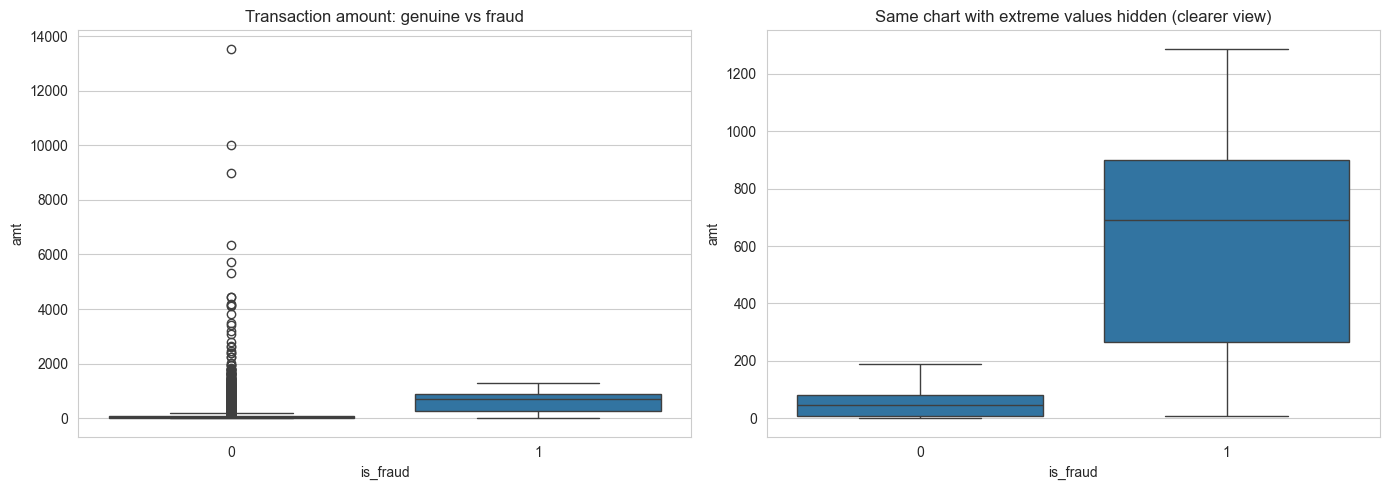

            count    mean     std  min     25%     50%     75%       max
is_fraud                                                                
0         49711.0   66.79  149.02  1.0    9.56   47.00   81.96  13536.84
1           289.0  552.02  392.67  7.3  266.28  690.94  899.48   1286.27


In [67]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))

sns.boxplot(x='is_fraud', y='amt', data=df_sample, ax=ax[0])
ax[0].set_title('Transaction amount: genuine vs fraud')

sns.boxplot(x='is_fraud', y='amt', data=df_sample, ax=ax[1], showfliers=False)
ax[1].set_title('Same chart with extreme values hidden (clearer view)')

plt.tight_layout()
plt.show()

print(df_sample.groupby('is_fraud')['amt'].describe().round(2))

The two boxes barely overlap, which means the amount is a strong clue.

**The typical fraud is about 15 times bigger than the typical genuine transaction.**
The middle value (median) for genuine transactions is ₹47, while for fraud it is ₹690.

Look more closely at the quartiles. For genuine transactions, 75% are below ₹81.96. For fraud,
75% are *above* ₹266.28. So three quarters of all frauds are larger than three quarters of all
genuine transactions. The two groups sit in almost completely different ranges.

**But there is something more interesting here.** Look at the maximum values:

- Largest genuine transaction: **₹13,536.84**
- Largest fraud transaction: **₹1,286.27**

The biggest transactions in the entire dataset are all genuine. Fraud seems to stop at around
₹1,300 and never goes higher.

This tells us something about how fraudsters behave. They do not empty the card in one huge
transaction, because a very large amount would immediately trigger the bank's alerts and the
card would be blocked. Instead they keep each transaction large enough to be worth their while
but small enough to slip past automatic checks.

This is useful and slightly counter-intuitive. A very large transaction is not automatically
suspicious. Fraud lives in a **middle band** — clearly above normal spending, but deliberately
below the level that sets off alarms.

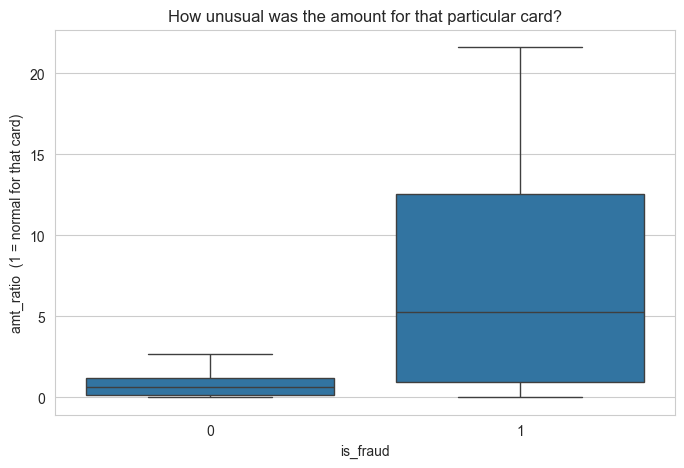

            count  mean   std   min   25%   50%    75%     max
is_fraud                                                      
0         49711.0  0.95  2.14  0.01  0.15  0.66   1.17  175.79
1           289.0  6.89  5.92  0.01  0.97  5.25  12.56   21.63


In [68]:
plt.figure(figsize=(8,5))
sns.boxplot(x='is_fraud', y='amt_ratio', data=df_sample, showfliers=False)
plt.title('How unusual was the amount for that particular card?')
plt.ylabel('amt_ratio  (1 = normal for that card)')
plt.show()

print(df_sample.groupby('is_fraud')['amt_ratio'].describe().round(2))

This column compares every transaction to what is normal **for that particular card**, and it
separates the two groups very clearly.

- A typical genuine transaction has a ratio of **0.66**, meaning people usually spend a bit
  less than their own average.
- A typical fraud has a ratio of **5.25**, meaning the thief spent over five times what the
  real owner normally spends.

That is roughly an **eight times difference** between the two groups.

Notice the same ceiling effect we saw with the amount. The highest ratio among genuine
transactions is 175.79, but among frauds it is only 21.63. Once again the most extreme values
in the data belong to genuine customers, not fraudsters. Real people occasionally make one
unusually large purchase — a flight ticket, a new phone — and that is normal behaviour. Thieves
stay within a narrower band to avoid being noticed.

**One honest limitation.** For fraud, the 25% mark is 0.97, which is very close to 1. That means
about a quarter of all frauds were roughly the *normal* amount for that card. These are the
difficult cases. A thief who spends a typical amount looks exactly like the real owner on this
measure, and no amount-based rule will catch them. We will need the other columns — the time of
night and the category — to find those.

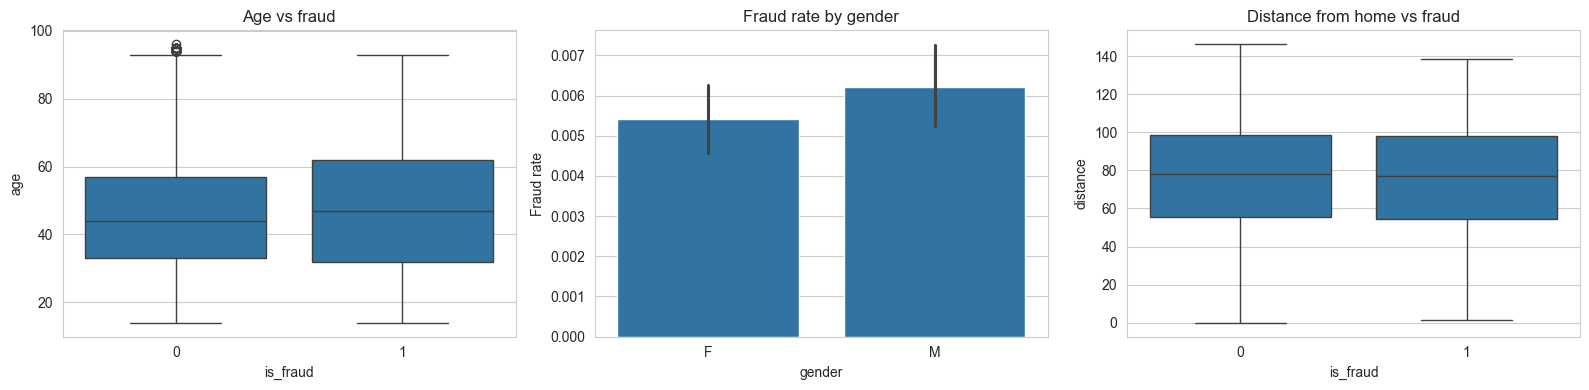

           age  distance
is_fraud                
0         44.0     78.27
1         47.0     77.14

gender
F    0.543
M    0.620
Name: is_fraud, dtype: float64


In [69]:
fig, ax = plt.subplots(1, 3, figsize=(16,4))

sns.boxplot(x='is_fraud', y='age', data=df_sample, ax=ax[0])
ax[0].set_title('Age vs fraud')

sns.barplot(x='gender', y='is_fraud', data=df_sample, ax=ax[1])
ax[1].set_ylabel('Fraud rate')
ax[1].set_title('Fraud rate by gender')

sns.boxplot(x='is_fraud', y='distance', data=df_sample, ax=ax[2])
ax[2].set_title('Distance from home vs fraud')

plt.tight_layout()
plt.show()

print(df_sample.groupby('is_fraud')[['age', 'distance']].median().round(2))
print()
print(df_sample.groupby('gender')['is_fraud'].mean().round(5) * 100)

These three columns tell a very different story from the earlier ones. All three are weak.

**Age:** genuine transactions have a median age of 44, fraud has 47. The two boxes look almost
identical. A three-year difference is far too small to be useful for identifying fraud.

**Gender:** the fraud rate is 0.543% for women and 0.620% for men. The difference is tiny, and
the black error bars on the chart overlap heavily, which means even this small gap could easily
be down to chance rather than a real pattern.

**Distance:** genuine transactions have a median distance of 78.27 km and frauds 77.14 km.
These are effectively the same number.

**The distance result is the important one, and we predicted it.**

Earlier, when we looked at the distribution of `distance`, we noticed it formed a neat
symmetric bell curve that stopped dead at 146 km — a shape that does not occur in real data.
We said then that it looked like the simulator had placed every merchant within a fixed radius
of the customer, and that the column would therefore probably be useless. This chart confirms
it: fraud happens at exactly the same distance from home as genuine spending.

This matters for the report. In real banking systems, distance from home is one of the
strongest fraud signals there is — a card used in another city minutes after being used locally
is an obvious red flag. Here that signal simply does not exist, because the data is simulated.

So this is a **limitation of the dataset, not a finding about fraud**. It would be wrong to
conclude "location does not matter for fraud detection". The honest conclusion is "this
particular simulated dataset does not contain any location signal to learn from".

We will keep `distance` in the data for now and let the correlation test confirm this a third
time before deciding whether to drop it.

### Multivariate analysis

So far we have looked at one column at a time, then two at a time. A pairplot shows every
numeric column against every other one in a single grid, coloured by fraud. It lets us spot
relationships between the features themselves, not just between each feature and fraud.

A pairplot compares every row with every other row, so we draw it on a smaller slice of
5,000 transactions to keep it fast. All 289 fraud cases are kept in so the red points stay
visible.

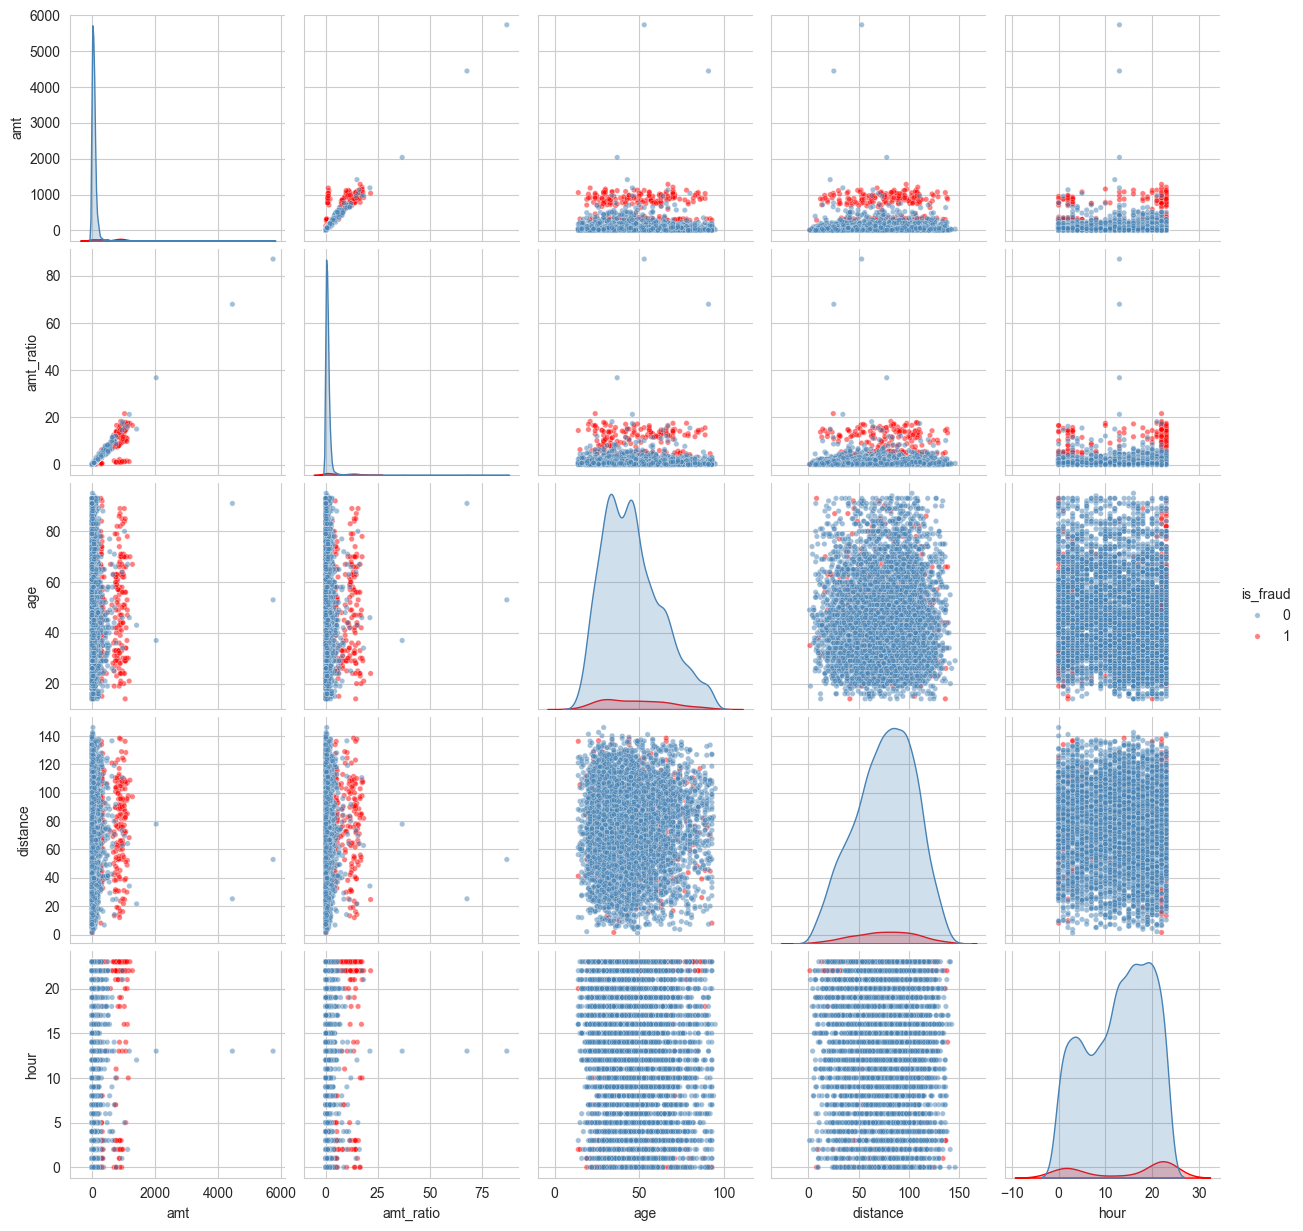

In [72]:
# Keep all the fraud cases, plus a random 5000 genuine ones, so fraud stays visible
fraud_rows = df_sample[df_sample['is_fraud']==1]
genuine_rows = df_sample[df_sample['is_fraud']==0].sample(5000, random_state=42)
pair_data = pd.concat([fraud_rows, genuine_rows])

sns.pairplot(pair_data[['amt', 'amt_ratio', 'age', 'distance', 'hour', 'is_fraud']],
             hue='is_fraud', palette={0:'steelblue', 1:'red'},
             plot_kws={'alpha':0.5, 's':15})
plt.show()

The pairplot shows us how the columns behave together, and three things stand out.

**1. Amount and hour together are much stronger than either one alone.**
Look at the `amt` vs `hour` panel. The red fraud points are not scattered randomly. They sit in
two tight bands — one at hours 22 and 23, another at hours 0 to 3 — and within those bands they
sit higher up than the blue points. So fraud is not just "a large amount" and not just "late at
night". It is **a large amount, late at night**. Either clue on its own would catch a lot of
innocent transactions. Together they are far more precise.

**2. Age and distance show no separation at all.**
In every panel involving `age` or `distance`, the red points are spread evenly through the blue
ones with no pattern. This is the third time distance has failed a test, after the odd bell
curve and the identical medians. We can now be confident it carries no signal.

**3. Amount and amt_ratio are related to each other.**
The `amt` vs `amt_ratio` panel shows the points forming a rising band rather than a shapeless
cloud. This makes sense, because `amt_ratio` was calculated *from* `amt`. When two input columns
are strongly related like this it is called **multicollinearity**, and it can confuse some
models. We will measure this properly using the VIF test in a later step and decide whether to
keep both.

The diagonal boxes show each column's own distribution, which we have already studied. The red
curves along the bottom are the fraud cases — note how the red curve for `amt` sits well to the
right of the blue one, and how the red curve for `hour` has two humps at the two ends of the
day.

## Checking for outliers

An outlier is a value that sits far away from the rest of the data. Usually we treat them as
errors and remove them, because they can drag a model in the wrong direction.

**But in fraud detection we have to be very careful here.** Fraud *is* unusual behaviour. The
strange, extreme values are often exactly the cases we are trying to catch. If we blindly
delete all the outliers, we may end up deleting the fraud itself and leave the model with
nothing to learn from.

So we will look at the outliers first and decide carefully, rather than removing them
automatically.

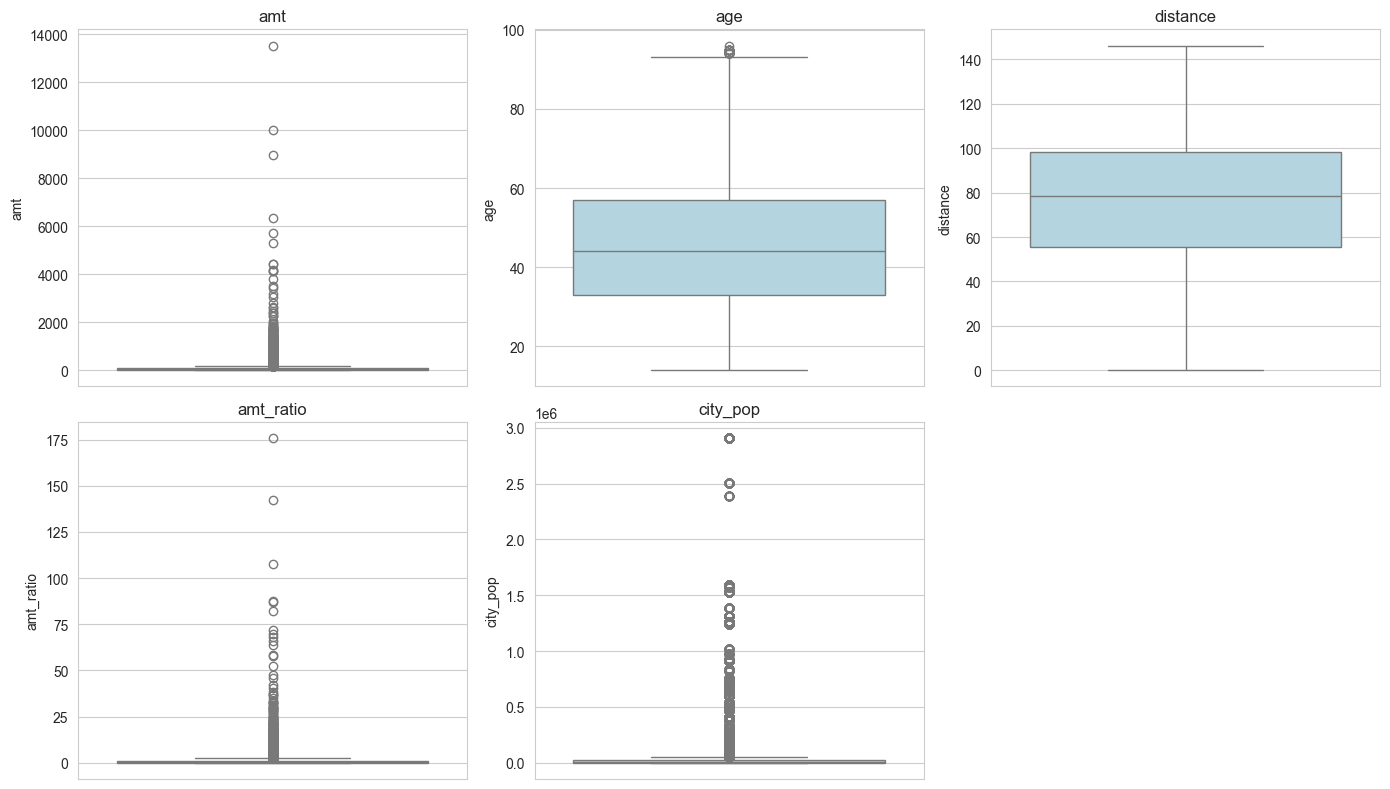

In [73]:
numerical_col = ['amt', 'age', 'distance', 'amt_ratio', 'city_pop']

plt.figure(figsize=(14,8))
plotnumber = 1

for col in numerical_col:
    ax = plt.subplot(2, 3, plotnumber)
    sns.boxplot(y=df_sample[col], color='lightblue')
    plt.title(col, fontsize=12)
    plotnumber += 1

plt.tight_layout()
plt.show()

The boxplots show heavy outliers in `amt`, `amt_ratio` and `city_pop`, a few in `age`, and
**none at all in `distance`** — its whiskers stretch neatly to both ends with nothing beyond
them, which is yet another sign that the column was artificially generated.

The standard method would be to remove these outliers using the IQR rule. But before doing
anything, let us actually measure how much fraud we would destroy by doing that.

In [74]:
# Finding the outliers in the amount column using the standard IQR rule
Q1 = df_sample['amt'].quantile(0.25)
Q3 = df_sample['amt'].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + 1.5 * IQR
lower_limit = Q1 - 1.5 * IQR

print("Lower limit:", round(lower_limit, 2))
print("Upper limit:", round(upper_limit, 2))
print()

outliers = df_sample[(df_sample['amt'] > upper_limit) | (df_sample['amt'] < lower_limit)]

print("Total transactions flagged as outliers:", len(outliers))
print("How many of them are fraud             :", outliers['is_fraud'].sum())
print()
print("Total fraud in the sample              :", df_sample['is_fraud'].sum())
print("Percentage of ALL fraud that would be lost:",
      round(100 * outliers['is_fraud'].sum() / df_sample['is_fraud'].sum(), 2), "%")

Lower limit: -99.71
Upper limit: 191.82

Total transactions flagged as outliers: 2551
How many of them are fraud             : 220

Total fraud in the sample              : 289
Percentage of ALL fraud that would be lost: 76.12 %


This is the most important decision in the whole project, and the numbers settle it completely.

The IQR rule flags **2,551 transactions** as outliers. Of those, **220 are fraud**. Our sample
only contains 289 frauds in total.

So if we had followed the standard textbook advice and removed the outliers, we would have
thrown away **76.12% of all the fraud in the dataset** before even starting to build a model.

Turn the numbers around and the point becomes even clearer:

- Among the 2,551 "outlier" transactions, **8.62%** are fraud.
- Among the other 47,449 normal-looking transactions, only **0.145%** are fraud.

An outlier transaction is roughly **59 times more likely to be fraud** than an ordinary one.

**So we are not removing any outliers.**

This is worth understanding properly, because it goes against what is usually taught. In most
projects an outlier is noise — a typing mistake, a broken sensor, a wrongly entered value. You
remove it so it does not distort the model.

In fraud detection the opposite is true. Fraud is *defined* by being unusual. A thief using a
stolen card behaves differently from the real owner, and that difference is exactly what shows
up as an outlier. Here the outliers are not noise. **The outliers are the answer.**

This is also the reason our anomaly detection method later on (DBSCAN) can work at all. DBSCAN
finds points that do not fit with the rest of the data, and we have just proved that those
points are heavily enriched with fraud.

We will keep every row. Instead of deleting extreme values, we will reduce their distorting
effect by transforming the skewed columns in the next step, which keeps the information while
making it easier for models to handle.

In [76]:
df_sample[['amt', 'age', 'distance', 'amt_ratio', 'city_pop']].skew().round(2)

amt          30.42
age           0.61
distance     -0.24
amt_ratio    27.50
city_pop      5.55
dtype: float64

## Anomaly detection using DBSCAN

In [79]:
from sklearn.preprocessing import RobustScaler

In [78]:
dbscan_features = ['amt', 'amt_ratio', 'hour', 'age']

X_db = df_sample[dbscan_features].copy()

scaler = RobustScaler()
X_db_scaled = scaler.fit_transform(X_db)

print("Shape:", X_db_scaled.shape)
for i, col in enumerate(dbscan_features):
    print(f"  {col:12s} min: {X_db_scaled[:,i].min():8.2f}   max: {X_db_scaled[:,i].max():8.2f}")

Shape: (50000, 4)
  amt          min:    -0.63   max:   185.09
  amt_ratio    min:    -0.64   max:   170.02
  hour         min:    -1.17   max:     0.75
  age          min:    -1.25   max:     2.17


### Choosing the eps value

DBSCAN needs two settings:

- **eps** — how close two points must be to count as neighbours
- **min_samples** — how many neighbours a point needs before it counts as part of a cluster

Guessing eps is the usual mistake. The standard method is a **k-distance plot**: for every point
we measure how far away its 4th nearest neighbour is, then sort those distances and plot them.
Most points sit in dense areas and have close neighbours, so the line stays low and flat. Near
the right-hand end it bends sharply upward — those are the isolated points. The height of that
bend is the natural eps value for this data.

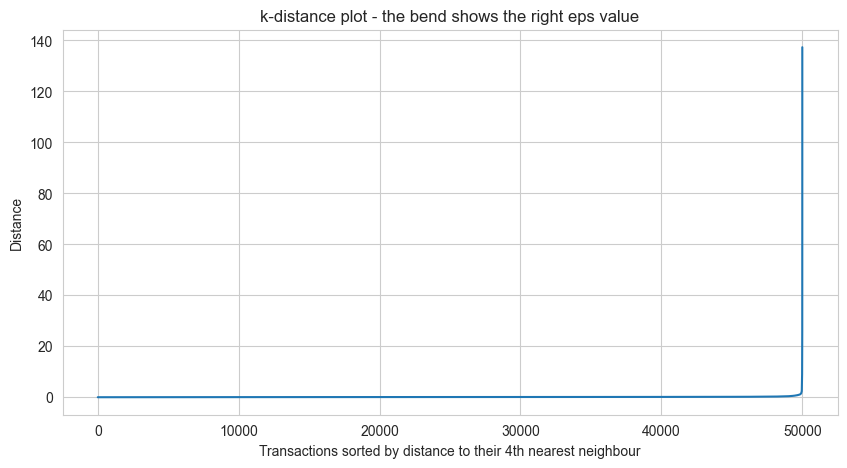

90th percentile: 0.159
95th percentile: 0.221
97th percentile: 0.300
99th percentile: 0.660
99.5th percentile: 0.959


In [80]:
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5).fit(X_db_scaled)
distances, indices = neighbors.kneighbors(X_db_scaled)

k_distances = np.sort(distances[:, 4])

plt.figure(figsize=(10,5))
plt.plot(k_distances)
plt.xlabel('Transactions sorted by distance to their 4th nearest neighbour')
plt.ylabel('Distance')
plt.title('k-distance plot - the bend shows the right eps value')
plt.grid(True)
plt.show()

for p in [90, 95, 97, 99, 99.5]:
    print(f"{p}th percentile: {np.percentile(k_distances, p):.3f}")

The line stays almost flat along the bottom and then shoots up almost vertically right at the
end. This is a good sign. It tells us the data has a dense core with a small number of isolated
points sitting far away from everything else.

The percentile values give us our candidates for eps:

- 90% of points are within **0.159** of their 4th neighbour
- 95% within **0.221**
- 97% within **0.300**
- 99% within **0.660**

Choosing eps sets how strict we are. A small eps means only the most extreme points are called
noise. A large eps means almost nothing gets flagged. Since fraud is 0.578% of our data, we
want to flag somewhere around 1% to 3% — enough to catch fraud without drowning an
investigation team in false alarms.

Rather than guessing, we will try several values and compare the results.

In [81]:
from sklearn.cluster import DBSCAN

results = []

for eps in [0.15, 0.22, 0.30, 0.50, 0.66]:
    labels = DBSCAN(eps=eps, min_samples=5, n_jobs=-1).fit_predict(X_db_scaled)

    is_noise = (labels == -1).astype(int)
    y = df_sample['is_fraud'].values

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = is_noise.sum()
    caught = ((is_noise == 1) & (y == 1)).sum()

    precision = caught / n_noise if n_noise else 0
    recall = caught / y.sum()

    results.append({
        'eps': eps,
        'clusters': n_clusters,
        'flagged': n_noise,
        'flagged_%': round(100 * n_noise / len(y), 2),
        'fraud_caught': caught,
        'precision_%': round(100 * precision, 2),
        'recall_%': round(100 * recall, 2)
    })

pd.DataFrame(results)

,eps,clusters,flagged,flagged_%,fraud_caught,precision_%,recall_%
0,0.15,72,3963,7.93,226,5.70,78.20
1,0.22,34,1953,3.91,221,11.32,76.47
2,0.30,19,1179,2.36,207,17.56,71.63
3,0.50,14,599,1.20,172,28.71,59.52
4,0.66,7,401,0.80,134,33.42,46.37


In [82]:
dbscan = DBSCAN(eps=0.30, min_samples=5, n_jobs=-1)
df_sample['cluster'] = dbscan.fit_predict(X_db_scaled)

df_sample['dbscan_anomaly'] = (df_sample['cluster'] == -1).astype(int)

print("Number of clusters found:", len(set(df_sample['cluster'])) - 1)
print()
print("Cluster sizes (top 10):")
print(df_sample['cluster'].value_counts().head(10))
print()
print("Fraud rate inside the flagged group vs the rest:")
print(df_sample.groupby('dbscan_anomaly')['is_fraud'].agg(['count', 'sum', 'mean']).round(5))

Number of clusters found: 19

Cluster sizes (top 10):
cluster
 0     48496
-1      1179
 1       149
 3        36
 4        24
 12       13
 10       13
 13       11
 5        11
 14        8
Name: count, dtype: int64

Fraud rate inside the flagged group vs the rest:
                count  sum     mean
dbscan_anomaly                     
0               48821   82  0.00168
1                1179  207  0.17557


DBSCAN found **19 clusters** plus a noise group.

- **Cluster 0 has 48,496 transactions** — 97% of everything. This is normal everyday spending.
  It all looks alike, so DBSCAN put it in one big group.
- **1,179 transactions were marked as noise (-1)** — they did not fit anywhere.
- **The other 18 clusters are very small**, from 149 transactions down to 8. These are small
  pockets of transactions that look like each other but not like the main group.

The main result:

| Group | Transactions | Frauds | Fraud rate |
|---|---|---|---|
| Flagged as anomaly | 1,179 | 207 | **17.557%** |
| Everything else | 48,821 | 82 | **0.168%** |

A flagged transaction is **104 times more likely to be fraud** than one that was not flagged.

Remember that DBSCAN never saw the `is_fraud` column. It did not know what fraud looks like.
It only found transactions sitting alone, away from the crowd — and those turned out to be
104 times more fraudulent.

This is useful in real life. A bank only finds out about fraud weeks later, when the customer
complains. A method that needs no labels can start working from day one.

In [83]:
cluster_profile = df_sample.groupby('cluster').agg(
    size=('is_fraud', 'size'),
    frauds=('is_fraud', 'sum'),
    fraud_rate=('is_fraud', 'mean'),
    median_amt=('amt', 'median'),
    median_ratio=('amt_ratio', 'median'),
    median_hour=('hour', 'median'),
    night_share=('is_night', 'mean')
).round(3)

cluster_profile['fraud_rate_%'] = (cluster_profile['fraud_rate'] * 100).round(2)
cluster_profile = cluster_profile.drop('fraud_rate', axis=1)

cluster_profile.sort_values('fraud_rate_%', ascending=False)

,size,frauds,median_amt,median_ratio,median_hour,night_share,fraud_rate_%
cluster,,,,,,,
11,8,5,301.505,4.535,2.0,1.000,62.5
13,11,4,328.230,5.240,1.0,1.000,36.4
-1,1179,207,451.530,6.170,14.0,0.356,17.6
3,36,1,267.805,4.470,19.0,0.167,2.8
0,48496,72,45.125,0.640,14.0,0.229,0.1
1,149,0,495.460,5.190,17.0,0.121,0.0
2,7,0,264.450,3.780,7.0,0.000,0.0
4,24,0,261.445,4.175,2.5,0.625,0.0
7,5,0,335.000,3.700,16.0,0.000,0.0


Reading the table from the top:

**Clusters 11 and 13 are almost pure fraud.** Cluster 11 is 62.5% fraud and cluster 13 is 36.4%.
Both are **100% night-time**, with median hours of 2 am and 1 am, amounts around ₹300 and
spending about 5 times the card's normal level. These are small tight pockets of night-time
fraud.

**The noise group (-1) holds most of the fraud** — 207 of the 289 frauds in our sample. Median
amount ₹451 and spending 6 times the card's normal level.

**Now the interesting part. Look at clusters 1, 4, 5, 6 and the rest — they have zero fraud.**

Cluster 1 has 149 transactions with a median amount of ₹495 and spending 5 times the card's
normal level. Those numbers look just as suspicious as the fraud clusters. Yet not one of them
is fraud.

This tells us something important about how fraud behaves:

- **Real fraud is scattered and isolated.** Each fraud is a one-off event, so DBSCAN cannot group
  them and dumps them into the noise pile.
- **Unusual but genuine spending forms tight little groups.** A customer who regularly makes large
  purchases creates a repeating pattern, and DBSCAN finds that pattern and gives it its own
  cluster.

So being unusual is not enough to be fraud. Being unusual **and alone** is what matters. A big
spender is unusual but consistent. A thief is unusual and never repeats.

This is exactly why DBSCAN suits this problem better than a simple "flag all large amounts" rule.
Such a rule would have flagged all 149 transactions in cluster 1 and been wrong every single time.

### Grouping the frauds into types

We now know which transactions are fraud. The last question is what **kinds** of fraud exist,
because a bank would respond differently to each kind.

To find this out we take only the confirmed fraud transactions and group them by their own
behaviour — amount, time of day and how unusual the spending was. We use KMeans for this,
which splits them into a fixed number of groups.

In [84]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

frauds = df_sample[df_sample['is_fraud'] == 1].copy()
print("Number of frauds to group:", len(frauds))

profile_cols = ['amt', 'amt_ratio', 'hour', 'is_night', 'age']
Z = RobustScaler().fit_transform(frauds[profile_cols])

# Trying different numbers of groups to see which fits best
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    print(f"  {k} groups: silhouette score = {silhouette_score(Z, km.labels_):.3f}")

Number of frauds to group: 289
  2 groups: silhouette score = 0.349
  3 groups: silhouette score = 0.314
  4 groups: silhouette score = 0.294
  5 groups: silhouette score = 0.319
  6 groups: silhouette score = 0.328


The silhouette scores are all between 0.29 and 0.35, which is a narrow range. Two groups scores
highest (0.349), but six groups is almost as good (0.328).

What this means is that fraud here does not fall into sharply separated types. The frauds sit
on a continuous range rather than in clearly separate boxes.

**We will use 4 groups.** Two groups would be too coarse to be useful for a bank, and the score
difference between 2 and 4 is small (0.349 against 0.294). We are choosing 4 for a more detailed
picture, not because the data insists on it — and it is better to say that openly than to
pretend the number came out of the maths.

In [85]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
frauds['fraud_type'] = kmeans.fit_predict(Z)

type_profile = frauds.groupby('fraud_type').agg(
    count=('amt', 'size'),
    median_amt=('amt', 'median'),
    median_ratio=('amt_ratio', 'median'),
    median_hour=('hour', 'median'),
    night_share=('is_night', 'mean'),
    median_age=('age', 'median')
).round(2)

type_profile['share_%'] = (100 * type_profile['count'] / len(frauds)).round(1)

print(type_profile.to_string())
print()
print("Most common category in each group:")
print(frauds.groupby('fraud_type')['category'].agg(lambda s: s.value_counts().idxmax()))

            count  median_amt  median_ratio  median_hour  night_share  median_age  share_%
fraud_type                                                                                
0              51      288.45          0.79          3.0         0.90        65.0     17.6
1              77      899.48         12.27         22.0         0.84        63.0     26.6
2              72      893.05         12.79         21.5         0.81        32.0     24.9
3              89      114.15          0.44          5.0         0.81        34.0     30.8

Most common category in each group:
fraud_type
0     grocery_pos
1    shopping_net
2    shopping_net
3     grocery_pos
Name: category, dtype: object


### The four types of fraud

| Type | Share | Amount | vs card's normal | Hour | Age | Category | Name |
|---|---|---|---|---|---|---|---|
| 1 | 26.6% | ₹899 | **12.3x** | 10 pm | 63 | shopping_net | Online spree — older cardholder |
| 2 | 24.9% | ₹893 | **12.8x** | 9:30 pm | 32 | shopping_net | Online spree — younger cardholder |
| 3 | 30.8% | ₹114 | **0.44x** | 5 am | 34 | grocery_pos | Cloned card — younger cardholder |
| 0 | 17.6% | ₹288 | **0.79x** | 3 am | 65 | grocery_pos | Cloned card — older cardholder |

All four types happen at night (80–90%), which we already knew. What separates them is the
**amount** and the **age of the victim**.

**Types 1 and 2 — the online spree (51.5% of all fraud).**
Someone has the card number and is shopping online late in the evening. They spend around ₹900,
which is about **12 times** what the real owner normally spends. The card is never physically
used, so this is what banks call card-not-present fraud. These are the loud, obvious frauds.

**Types 0 and 3 — the cloned card (48.4% of all fraud).**
These happen at a grocery till, so the thief is using a physical copy of the card. They come
much later at night, 3 am to 5 am, and the amounts are small — ₹114 and ₹288.

**Now look carefully at the ratio column for types 0 and 3: 0.79 and 0.44.**

Both are **below 1**. These thieves are spending *less* than the real owner normally spends.

This is the most important finding in the whole typology, and it connects back to something we
noticed earlier. When we studied `amt_ratio` we saw that a quarter of frauds had a ratio near 1,
and said those would be hard to catch. Now we know exactly who they are: nearly half of all
fraud is deliberately small.

The reason is simple. A thief who has cloned a card does not want to be noticed. A ₹114 grocery
purchase at 5 am looks completely harmless next to a ₹900 online order. Any rule based on "flag
large amounts" would miss this half of the fraud entirely.

So the two halves need completely different defences. The online spree is caught by the amount.
The cloned card can only be caught by the **time** — no genuine customer is buying groceries at
5 am.

In [86]:
check = frauds.groupby('fraud_type').agg(
    total=('is_fraud', 'size'),
    caught_by_dbscan=('dbscan_anomaly', 'sum')
)
check['caught_%'] = (100 * check['caught_by_dbscan'] / check['total']).round(1)
check['median_ratio'] = frauds.groupby('fraud_type')['amt_ratio'].median().round(2)

print(check.to_string())

            total  caught_by_dbscan  caught_%  median_ratio
fraud_type                                                 
0              51                26      51.0          0.79
1              77                77     100.0         12.27
2              72                72     100.0         12.79
3              89                32      36.0          0.44


### How well DBSCAN caught each type

| Type | Name | Total | Caught | Caught % | Ratio |
|---|---|---|---|---|---|
| 1 | Online spree — older | 77 | 77 | **100%** | 12.27 |
| 2 | Online spree — younger | 72 | 72 | **100%** | 12.79 |
| 0 | Cloned card — older | 51 | 26 | **51%** | 0.79 |
| 3 | Cloned card — younger | 89 | 32 | **36%** | 0.44 |

The result is exactly what we predicted from the ratio column.

**DBSCAN caught every single one of the loud frauds.** All 149 of the online sprees, where the
thief spent 12 times the card's normal amount. Not one was missed.

**It missed most of the quiet ones.** Only 36% of type 3 was caught. Of the 82 frauds that got
away, 57 came from this one type.

The reason is straightforward. DBSCAN finds points that sit away from the crowd. A ₹114 grocery
purchase does not sit away from the crowd — it looks like thousands of ordinary transactions.
The only thing odd about it is that it happened at 5 am, and the hour column had almost no
influence on the distance calculation compared to the amount.

**What this means for the project.**

Our anomaly detection has a clear blind spot, and we have measured exactly where it is: small
purchases made with cloned cards in the early hours. This is not a failure of the method. It is
a known and quantified limit, and knowing precisely where a system is weak is far more useful
than a single overall accuracy figure.

It also tells us what to do next. The supervised models in the following section can use the
hour directly as a feature instead of burying it inside a distance calculation, so they should
be able to catch some of what DBSCAN missed. We will check whether they actually do.

## Correlation between the features and fraud

Correlation measures how strongly two columns move together. It runs from -1 to +1. A value
near 0 means no relationship at all.

Before building models we check which columns actually relate to fraud, and whether any two
columns are so similar that keeping both would be pointless.

In [88]:
from sklearn.preprocessing import OrdinalEncoder

df_model = df_sample.copy()
df_model['gender'] = df_model['gender'].map({'F': 0, 'M': 1})

# Encoding category in order of its fraud rate, so the numbers carry real meaning
cat_order = df_sample.groupby('category')['is_fraud'].mean().sort_values().index
cat_map = {cat: i for i, cat in enumerate(cat_order)}
df_model['category'] = df_model['category'].map(cat_map)

cols = ['amt', 'amt_ratio', 'category', 'hour', 'is_night', 'age',
        'distance', 'city_pop', 'gender', 'is_fraud']

print(df_model[cols].corr()['is_fraud'].sort_values(ascending=False).round(4))

is_fraud     1.0000
amt          0.2359
amt_ratio    0.2022
is_night     0.1087
category     0.0663
hour         0.0153
age          0.0093
gender       0.0051
city_pop     0.0033
distance    -0.0004
Name: is_fraud, dtype: float64


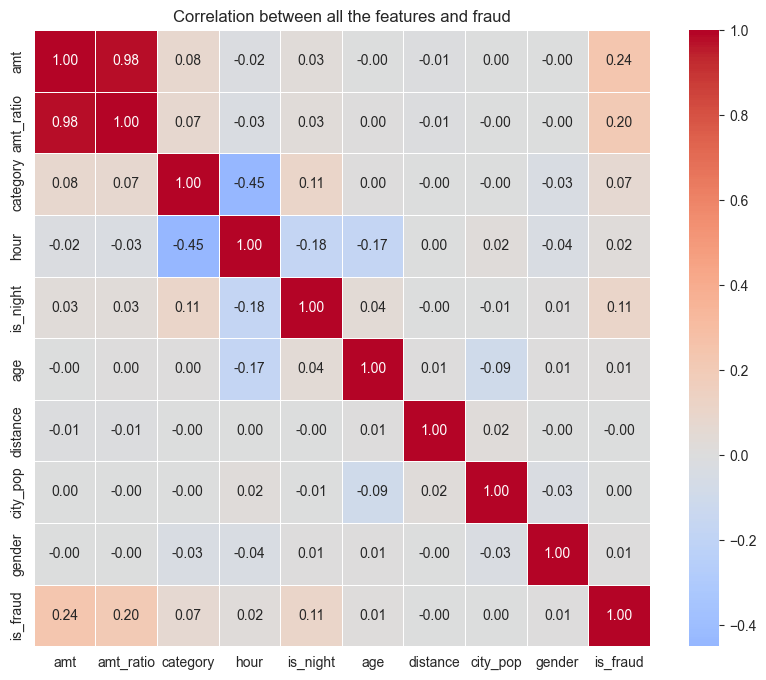

In [89]:
plt.figure(figsize=(10,8))
sns.heatmap(df_model[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, square=True)
plt.title('Correlation between all the features and fraud')
plt.show()

### Reading the heatmap

The bottom row shows how each feature relates to fraud. `amt` is the strongest at 0.24, then
`amt_ratio` at 0.20 and `is_night` at 0.11. `distance` is exactly -0.00, which is the fifth
test it has failed, so we can drop it with confidence.

**One problem needs fixing.** `amt` and `amt_ratio` correlate at 0.98 with each other. They are
almost the same column. This happens because most cards have a similar average spending level,
so dividing by that average barely changes anything. We built `amt_ratio` hoping it would add
new information about each card's personal habits, and it turns out it adds very little. The
VIF test will confirm this and then we drop one.

**But the bigger lesson is this.** All the correlations look small, the best being only 0.24. It
would be easy to decide that none of our features work. That would be wrong. `is_night` shows
only 0.11 here, yet we proved earlier that night transactions are 17 times more likely to be
fraud and that 83% of all fraud happens at night.

Correlation looks at all rows together, and our 49,711 genuine transactions drown out the 289
frauds. So for rare events, a low correlation does not mean a useless feature. Anyone who
trusted only this heatmap would have thrown away the best feature in the dataset.

In [90]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

features = ['amt', 'amt_ratio', 'category', 'hour', 'is_night', 'age', 'city_pop', 'gender']
X_vif = df_model[features]

vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

vif.sort_values('VIF', ascending=False)

,Feature,VIF
0,amt,24.744254
1,amt_ratio,24.648888
5,age,4.729389
3,hour,2.902432
2,category,2.851690
7,gender,1.743951
4,is_night,1.316970
6,city_pop,1.085070


`amt` and `amt_ratio` both have a VIF of about 24.7, far above the limit of 10. This confirms
what the heatmap showed — they are carrying the same information twice.

Every other feature is comfortably below 5, so there is no other problem.

We drop `amt_ratio` and keep `amt`. The plain amount has a slightly stronger link to fraud
(0.24 against 0.20) and is much easier to explain. Then we check the VIF again to be sure the
problem is gone.

In [91]:
features = ['amt', 'category', 'hour', 'is_night', 'age', 'city_pop', 'gender']
X_vif = df_model[features]

vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]

vif.sort_values('VIF', ascending=False)

,Feature,VIF
4,age,4.713398
2,hour,2.900242
1,category,2.849762
6,gender,1.743951
3,is_night,1.316811
0,amt,1.204543
5,city_pop,1.084955


After dropping `amt_ratio`, every VIF is below 5 and `amt` has fallen from 24.7 to 1.20. There
is no multicollinearity left, so we can move on to building the models.

In [92]:
x = df_model[['amt', 'category', 'hour', 'is_night', 'age', 'city_pop', 'gender']]
y = df_model['is_fraud']

print("Features shape:", x.shape)
print("Label shape   :", y.shape)
print()
print(y.value_counts())

Features shape: (50000, 7)
Label shape   : (50000,)

is_fraud
0    49711
1      289
Name: count, dtype: int64


In [93]:
x_train, x_test, y_train, y_test = train_test_split(x, y,
                                                    test_size=0.25,
                                                    stratify=y,
                                                    random_state=42)

print("Training set:", x_train.shape, " frauds:", y_train.sum())
print("Test set    :", x_test.shape, " frauds:", y_test.sum())

Training set: (37500, 7)  frauds: 217
Test set    : (12500, 7)  frauds: 72


## Feature scaling

Our columns are on very different scales. `amt` can run into thousands while `is_night` is only
0 or 1. Some models, especially Logistic Regression, would treat the large numbers as more
important simply because they are larger.

Scaling puts every column on the same footing. We fit the scaler on the training data only and
then apply it to the test data. Fitting it on everything would leak information from the test
set into the training process.

In [94]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Scaled training set:", x_train_scaled.shape)
print("Scaled test set    :", x_test_scaled.shape)

Scaled training set: (37500, 7)
Scaled test set    : (12500, 7)


## Building the classification models

We will try four different algorithms and compare them.

Instead of SMOTE, we use **`class_weight='balanced'`**. This tells the model to treat each fraud
case as roughly 172 times more costly to miss than a genuine one. It fixes the imbalance using
only the real data, without inventing any fake fraud examples.

We judge the models on four scores:

- **Precision** — out of everything the model flagged, how much was really fraud
- **Recall** — out of all the real frauds, how many did the model catch
- **ROC-AUC** — overall ability to separate the two classes
- **PR-AUC** — the same idea but focused on the rare class, which is the fairer score here

We do **not** use accuracy, because predicting "not fraud" every time would already score 99.4%.

In [95]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

results = []

def evaluate(name, model, use_scaled=False):
    xtr = x_train_scaled if use_scaled else x_train
    xte = x_test_scaled if use_scaled else x_test

    if name == 'Gradient Boosting':
        sw = compute_sample_weight('balanced', y_train)
        model.fit(xtr, y_train, sample_weight=sw)
    else:
        model.fit(xtr, y_train)

    pred = model.predict(xte)
    prob = model.predict_proba(xte)[:, 1]

    results.append({
        'Model': name,
        'Precision': round(precision_score(y_test, pred, zero_division=0), 3),
        'Recall': round(recall_score(y_test, pred), 3),
        'F1': round(f1_score(y_test, pred), 3),
        'ROC_AUC': round(roc_auc_score(y_test, prob), 3),
        'PR_AUC': round(average_precision_score(y_test, prob), 3)
    })
    return model

lr = evaluate('Logistic Regression',
              LogisticRegression(max_iter=1000, class_weight='balanced'), use_scaled=True)

dt = evaluate('Decision Tree',
              DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=42))

rf = evaluate('Random Forest',
              RandomForestClassifier(n_estimators=100, max_depth=12,
                                     class_weight='balanced', random_state=42, n_jobs=-1))

gb = evaluate('Gradient Boosting',
              GradientBoostingClassifier(n_estimators=100, random_state=42))

pd.DataFrame(results).sort_values('PR_AUC', ascending=False)

,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
2,Random Forest,0.978,0.611,0.752,0.957,0.776
3,Gradient Boosting,0.210,0.847,0.337,0.973,0.698
1,Decision Tree,0.229,0.819,0.358,0.917,0.525
0,Logistic Regression,0.030,0.764,0.058,0.925,0.285


### Comparing the models

Random Forest has the best PR-AUC at 0.776. But the models behave very differently in practice.
Our test set has 12,500 transactions with 72 frauds.

**Random Forest** flagged about 45 transactions and 44 were fraud — only one false alarm. But it
missed 28 frauds.

**Gradient Boosting** caught 61 frauds, 17 more than Random Forest. But it flagged about 290
transactions, so a team would have to check 229 innocent ones.

**Logistic Regression is the warning story.** It caught 55 frauds, but flagged about 1,833
transactions to do it. Out of every 100 transactions it called fraud, only 3 really were.

**ROC-AUC and PR-AUC disagree here.** Gradient Boosting has the better ROC-AUC (0.973 vs 0.957),
but Random Forest clearly wins on PR-AUC (0.776 vs 0.698). Logistic Regression shows why this
matters: its ROC-AUC is 0.925, which looks excellent, but its precision is 0.030, which is
useless.

ROC-AUC gives credit for correctly spotting the 49,711 genuine transactions, which is the easy
part. PR-AUC only looks at how well the rare frauds are handled. For fraud work, PR-AUC is the
score to trust.